In [75]:
import pandas as pd
import numpy as np
import time

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, ShuffleSplit, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ShuffleSplit

from xgboost import XGBRegressor

from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import joblib

sns.set(style="whitegrid", palette="muted", font_scale=1.1)

### Loading the training and the test dataframes
---

In [76]:
train_df = pd.read_csv('/kaggle/input/mlp-term-3-2025-kaggle-assignment-1/train.csv')
test_df = pd.read_csv('/kaggle/input/mlp-term-3-2025-kaggle-assignment-1/test.csv')

### Summary of Data Types

| Type | Columns |
|------|----------|
| **Numeric** | id, bath, balcony, price |
| **Categorical** | area_type, availability, location, size, total_sqft (needs conversion) |

---

In [77]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            10000 non-null  int64  
 1   area_type     10000 non-null  object 
 2   availability  10000 non-null  object 
 3   location      9999 non-null   object 
 4   size          9987 non-null   object 
 5   total_sqft    9967 non-null   float64
 6   bath          9936 non-null   float64
 7   balcony       9525 non-null   float64
 8   price         10000 non-null  float64
dtypes: float64(4), int64(1), object(4)
memory usage: 703.3+ KB


In [78]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3320 entries, 0 to 3319
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            3320 non-null   int64  
 1   area_type     3320 non-null   object 
 2   availability  3320 non-null   object 
 3   location      3320 non-null   object 
 4   size          3317 non-null   object 
 5   total_sqft    3307 non-null   float64
 6   bath          3311 non-null   float64
 7   balcony       3186 non-null   float64
dtypes: float64(3), int64(1), object(4)
memory usage: 207.6+ KB


### Descriptive Statistics — Numerical Columns

- **Total Square Feet (`total_sqft`)**  
  - Mean area ≈ **1570 sq.ft**, but max value (52,272 sq.ft) shows **extreme outliers**.  
  - Median = **1279 sq.ft**, indicating most homes are around this size.

- **Bathrooms (`bath`)**  
  - Average ≈ **2.7**, with a maximum of **18**, showing some luxury properties.  
  - 75% of houses have **3 or fewer** bathrooms.

- **Balconies (`balcony`)**  
  - Median = **2**, suggesting most homes have 1–2 balconies.  
  - Some properties have none (min = 0).

- **Price (`price`)**  
  - Mean ≈ **₹113.3 lakhs**, median = **₹72 lakhs** → distribution is **right-skewed**, meaning high-value luxury properties exist.  
  - Max = **₹3600 lakhs**, confirming significant outliers.

- **ID (`id`)**  
  - Sequential identifier, not used in analysis or modeling.

---

#### Key Observations

- The dataset includes **missing values** in `total_sqft`, `bath`, and `balcony`.  
- **Outlier treatment** may be required for `total_sqft` and `price`.  
- Consider **log transformation** of `price` to normalize its distribution.  
- **Feature scaling** or normalization can be useful before model training.

---
 
*Training Dataset Size: 10,000 samples*
*Training Dataset Size: 3,320 samples*

In [79]:
numeric_cols = train_df.select_dtypes(include=['int64', 'float64'])
numeric_cols.describe()

,id,total_sqft,bath,balcony,price
count,10000.00000,9967.000000,9936.000000,9525.000000,10000.000000
mean,4999.50000,1570.095822,2.692029,1.585302,113.275879
std,2886.89568,1302.566836,1.274172,0.814347,151.802643
min,0.00000,1.000000,1.000000,0.000000,8.000000
25%,2499.75000,1100.000000,2.000000,1.000000,50.000000
50%,4999.50000,1279.000000,2.000000,2.000000,72.000000
75%,7499.25000,1682.500000,3.000000,2.000000,120.000000
max,9999.00000,52272.000000,18.000000,3.000000,3600.000000


In [80]:
numeric_cols = test_df.select_dtypes(include=['int64', 'float64'])
numeric_cols.describe()

,id,total_sqft,bath,balcony
count,3320.000000,3307.000000,3311.000000,3186.000000
mean,1659.500000,1528.073686,2.694352,1.581607
std,958.545774,1020.450754,1.525878,0.826044
min,0.000000,5.000000,1.000000,0.000000
25%,829.750000,1100.000000,2.000000,1.000000
50%,1659.500000,1270.000000,2.000000,2.000000
75%,2489.250000,1660.000000,3.000000,2.000000
max,3319.000000,30400.000000,40.000000,3.000000


### Missing Values — Identification
- **Balcony (`balcony`)**  
  - Number of missing values = **475** (4.75%).  
  - All of them are of `Numeric`type
- **Bathrooms (`bath`)**  
  - Number of missing values = **64** (0.64%).  
  - All of them are of `Numeric`type
- **Square Feet (`total_sqft`)**  
  - Number of missing values = **33** (0.33%).  
  - All of them are of `Mixed`(numerric + text) type
- **Size (`size`)**  
  - Number of missing values = **13** (0.13%).  
  - All of them are of `Categorical`type
- **Location (`location`)**  
  - Number of missing values = **1** (0.01%).  
  - All of them are of `Categorical`type

In [81]:
missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

balcony       475
bath           64
total_sqft     33
size           13
location        1
dtype: int64


In [82]:
missing = test_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

balcony       134
total_sqft     13
bath            9
size            3
dtype: int64


### Missing Value Handling

| Column | Missing Values | Strategy Used |
|---------|----------------|----------------|
| `total_sqft` | Yes | Filled with **median** value |
| `bath` | Yes | Filled with **median** value |
| `balcony` | Yes | Filled with **median** value |
| `price` | No | Target variable — retained |
| `area_type` | Possible | Filled with **mode** (most frequent) |
| `availability` | Possible | Filled with **mode** |
| `location` | Possible | Filled with **mode** |
| `size` | Possible | Filled with **mode** before numeric conversion |

In [83]:
num_cols = ['total_sqft', 'bath', 'balcony', 'price']
for col in num_cols:
    train_df.loc[:, col] = train_df.loc[:, col].fillna(train_df.loc[:, col].median())


cat_cols = ['area_type', 'availability', 'location', 'size']

for col in cat_cols:
    train_df.loc[:, col] = train_df.loc[:, col].fillna(train_df.loc[:, col].mode()[0])

In [84]:
num_cols = ['total_sqft', 'bath', 'balcony']
for col in num_cols:
    test_df.loc[:, col] = test_df.loc[:, col].fillna(test_df.loc[:, col].median())


cat_cols = ['area_type', 'availability', 'location', 'size']

for col in cat_cols:
    test_df.loc[:, col] = test_df.loc[:, col].fillna(test_df.loc[:, col].mode()[0])

In [85]:
train_df.isnull().sum()

id              0
area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64

In [87]:
tr_m1 = train_df.copy()

### Resolving inconsistencies in the features 
As you can see there are `Bedroom` and `BHK` in the `size` column which essentially the same hence I decided to only extract the integer part of the String and created a new column `rooms`
| Before | After |
|:--------|----:|
| 3 BHK | 3 |
| 3 Bedroom | 3 |

In [88]:
tr_m1['size'].unique()

array(['3 BHK', '2 BHK', '3 Bedroom', '5 Bedroom', '4 BHK', '1 BHK',
       '4 Bedroom', '6 BHK', '6 Bedroom', '8 Bedroom', '8 BHK',
       '1 Bedroom', '2 Bedroom', '5 BHK', '7 Bedroom', '7 BHK', '1 RK',
       '9 Bedroom', '10 Bedroom', '9 BHK', '16 BHK', '13 BHK',
       '12 Bedroom', '10 BHK', '14 BHK', '11 BHK', '18 Bedroom'],
      dtype=object)

In [89]:
tr_m1['rooms'] = tr_m1['size'].apply(lambda x: int(str(x).split(' ')[0]) if pd.notnull(x) else None)

tr_m1.head()

,id,area_type,availability,location,size,total_sqft,bath,balcony,price,rooms
0,0,type_I,Ready To Move,Banashankari 2 nd Stage,3 BHK,1030.0,2.0,2.0,77.25,3
1,1,type_I,Ready To Move,Balagere,2 BHK,1210.0,2.0,1.0,83.00,2
2,2,type_I,17-Oct,Banashankari Stage V,3 BHK,1540.0,3.0,2.0,48.51,3
3,3,type_I,Ready To Move,Thigalarapalya,3 BHK,1830.0,4.0,2.0,135.00,3
4,4,type_III,Ready To Move,arudi,3 Bedroom,1279.0,2.0,0.0,80.00,3


### Dimensionality Reduction for Location
As you can see the we have more than **1176** unique locations of which **983** have less than or equal to 10 properties. This will cause when encoding this as a categorical data. Hence I reclassified it into `Others` for those location with less than or equal to 10 property. And now we only **193** unique `location` which is significantly lesser.

In [135]:
len(tr_m1['location'].unique())

193

In [91]:
len(tr_m1['location'].unique())
tr_m1.head()

,id,area_type,availability,location,size,total_sqft,bath,balcony,price,rooms
0,0,type_I,Ready To Move,Banashankari 2 nd Stage,3 BHK,1030.0,2.0,2.0,77.25,3
1,1,type_I,Ready To Move,Balagere,2 BHK,1210.0,2.0,1.0,83.00,2
2,2,type_I,17-Oct,Banashankari Stage V,3 BHK,1540.0,3.0,2.0,48.51,3
3,3,type_I,Ready To Move,Thigalarapalya,3 BHK,1830.0,4.0,2.0,135.00,3
4,4,type_III,Ready To Move,arudi,3 Bedroom,1279.0,2.0,0.0,80.00,3


In [92]:
tr_m1['location'] = tr_m1['location'].apply(lambda x: x.strip())
location_stats = tr_m1.groupby('location').size().sort_values(ascending=False)
location_stats

location
Whitefield              404
Sarjapur  Road          301
Electronic City         228
Kanakpura Road          209
Thanisandra             186
                       ... 
Kalkere Channasandra      1
Kamdhenu Nagar            1
Kanakapur main road       1
Kanakapura  Rod           1
whitefiled                1
Length: 1176, dtype: int64

In [93]:
len(location_stats[location_stats<=10])
location_with_less_than_10 = location_stats[location_stats<=10]

In [94]:
tr_m1['location'] = tr_m1['location'].apply(lambda x: 'Other' if x in location_with_less_than_10 else x)

tr_m2 = tr_m1.copy()
len(tr_m2['location'].unique())

193

### Duplicate Record Handling
Duplicate records can distort model training by repeating identical data points.  
This step ensures only **unique house listings** remain in the dataset.

But from the cells below we can observe that we have duplicate entries in both the data sets

In [95]:
tr_m2_duplicates = tr_m2.duplicated()

tr_m2_duplicates.sum()

0

### Outlier Removal from the dataset

First I created `price_per_sqft` to reference and identify the relationships and market trend and practices like:
- Typically in India bedrooms area generally between 140 and 300 sqft (Avg. 220 sqft)
- Also, generally a majority of Indian households only have a sigle bathroom, but it can go up, in my case I assume that a house will have bedrooms with attached baths and **1** additional for guests.

In [96]:
tr_m2['cost_per_area'] = tr_m2['price']*100000/tr_m2['total_sqft']
tr_m2.head()

,id,area_type,availability,location,size,total_sqft,bath,balcony,price,rooms,cost_per_area
0,0,type_I,Ready To Move,Other,3 BHK,1030.0,2.0,2.0,77.25,3,7500.000000
1,1,type_I,Ready To Move,Balagere,2 BHK,1210.0,2.0,1.0,83.00,2,6859.504132
2,2,type_I,17-Oct,Other,3 BHK,1540.0,3.0,2.0,48.51,3,3150.000000
3,3,type_I,Ready To Move,Thigalarapalya,3 BHK,1830.0,4.0,2.0,135.00,3,7377.049180
4,4,type_III,Ready To Move,Other,3 Bedroom,1279.0,2.0,0.0,80.00,3,6254.886630


In [97]:
bed_area_thrushhold = tr_m2[tr_m2['total_sqft']/tr_m2['rooms']<220]
# bed_area_thrushhold.head()
len(bed_area_thrushhold)
tr_m2.shape

(10000, 11)

In [98]:
tr_m3 = tr_m2[~(tr_m2['total_sqft']/tr_m2['rooms']<220)]
tr_m3.shape

(9643, 11)

In [99]:
tr_m3['cost_per_area'].describe()

count      9643.000000
mean       6453.013104
std        4463.068287
min         267.829813
25%        4226.639701
50%        5347.985348
75%        7058.823529
max      176470.588235
Name: cost_per_area, dtype: float64

In [100]:
mean = np.mean(tr_m3['cost_per_area'])
stdv = np.std(tr_m3['cost_per_area'])

check = tr_m3[(tr_m3['cost_per_area']>(mean-stdv)) & (tr_m3['cost_per_area']>(mean+stdv))]

check.shape

(870, 11)

In [101]:
def remove_outlier_cpa(df):
    output_df = pd.DataFrame()
    for key, subdf in df.groupby('location'):
        mean = np.mean(subdf['cost_per_area'])
        stdv = np.std(subdf['cost_per_area'])
        updated_df = subdf[(subdf['cost_per_area'] > (mean - stdv)) & (subdf['cost_per_area'] < (mean + stdv))]
        output_df = pd.concat([output_df, updated_df], ignore_index=True)

    return output_df

tr_m4 = remove_outlier_cpa(tr_m3)

tr_m4.shape

(7896, 11)

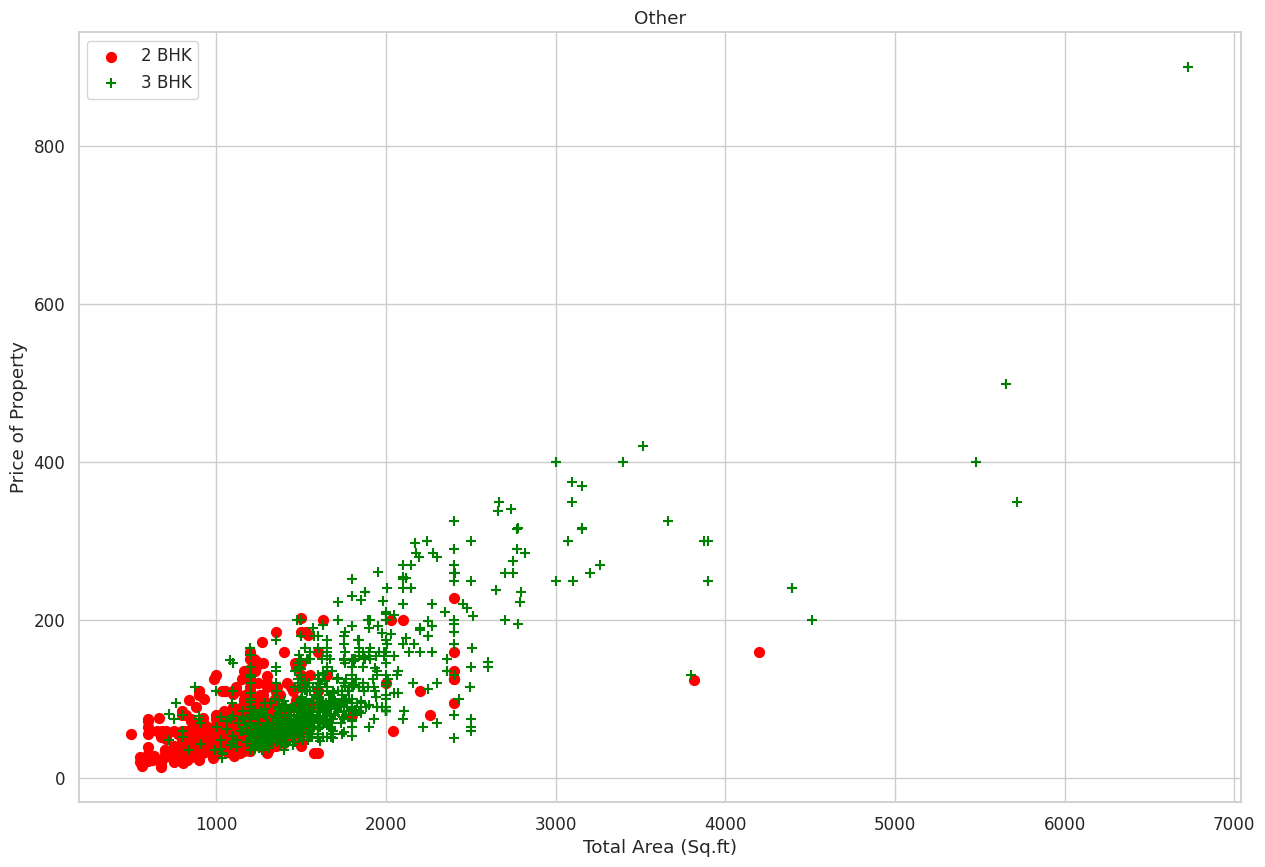

In [102]:
def create_scatter_plot(df, location):
    bhk2 = df[(df['location'] == location) & (df['rooms'] == 2)]
    bhk3 = df[(df['location'] == location) & (df['rooms'] == 3)]
    matplotlib.rcParams['figure.figsize'] = (15,10)
    plt.scatter(bhk2['total_sqft'], bhk2['price'], color='red', label='2 BHK', s=50)
    plt.scatter(bhk3['total_sqft'], bhk3['price'], marker='+', color='green', label='3 BHK', s=50)
    plt.xlabel("Total Area (Sq.ft)")
    plt.ylabel("Price of Property")
    plt.title(location)
    plt.legend()

create_scatter_plot(tr_m4, "Other")

In [103]:
def remove_bhk_outlier(df):
    excluded_index = np.array([])
    for location, location_df in df.groupby('location'):
        room_stats = {}
        for room, rooms_df in location_df.groupby('rooms'):
            room_stats[room] = {
                'mean': np.mean(rooms_df['cost_per_area']),
                'stdv': np.std(rooms_df['cost_per_area']),
                'count': rooms_df.shape[0]
            }
        for room, rooms_df in location_df.groupby('rooms'):
            stats = room_stats.get(room-1)
            if stats and stats['count']>5:
                excluded_index = np.append(excluded_index, rooms_df[rooms_df['cost_per_area']<(stats['mean'])].index.values)
    return df.drop(excluded_index, axis='index')

tr_m5 = remove_bhk_outlier(tr_m4)

tr_m5.shape

(5499, 11)

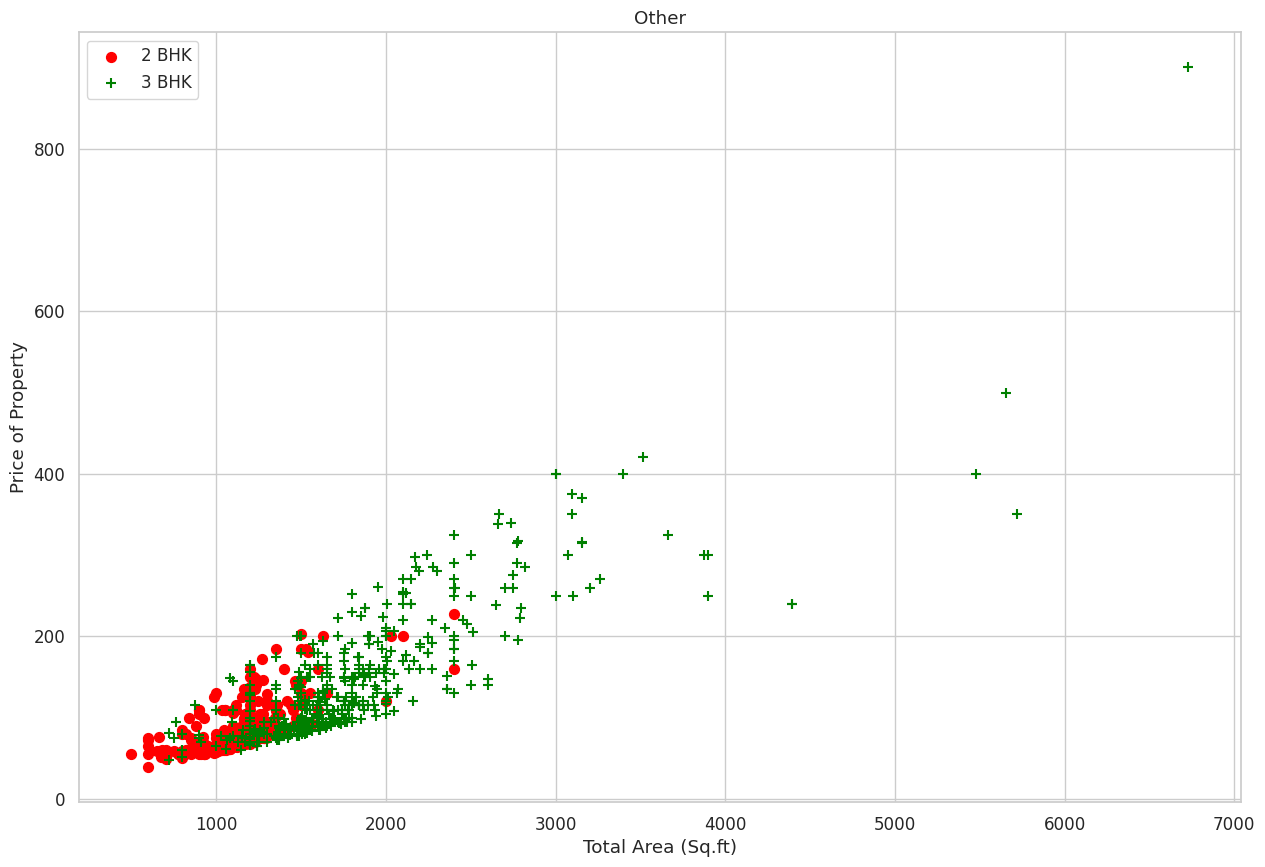

In [104]:
create_scatter_plot(tr_m5, "Other")

Text(0, 0.5, 'Count')

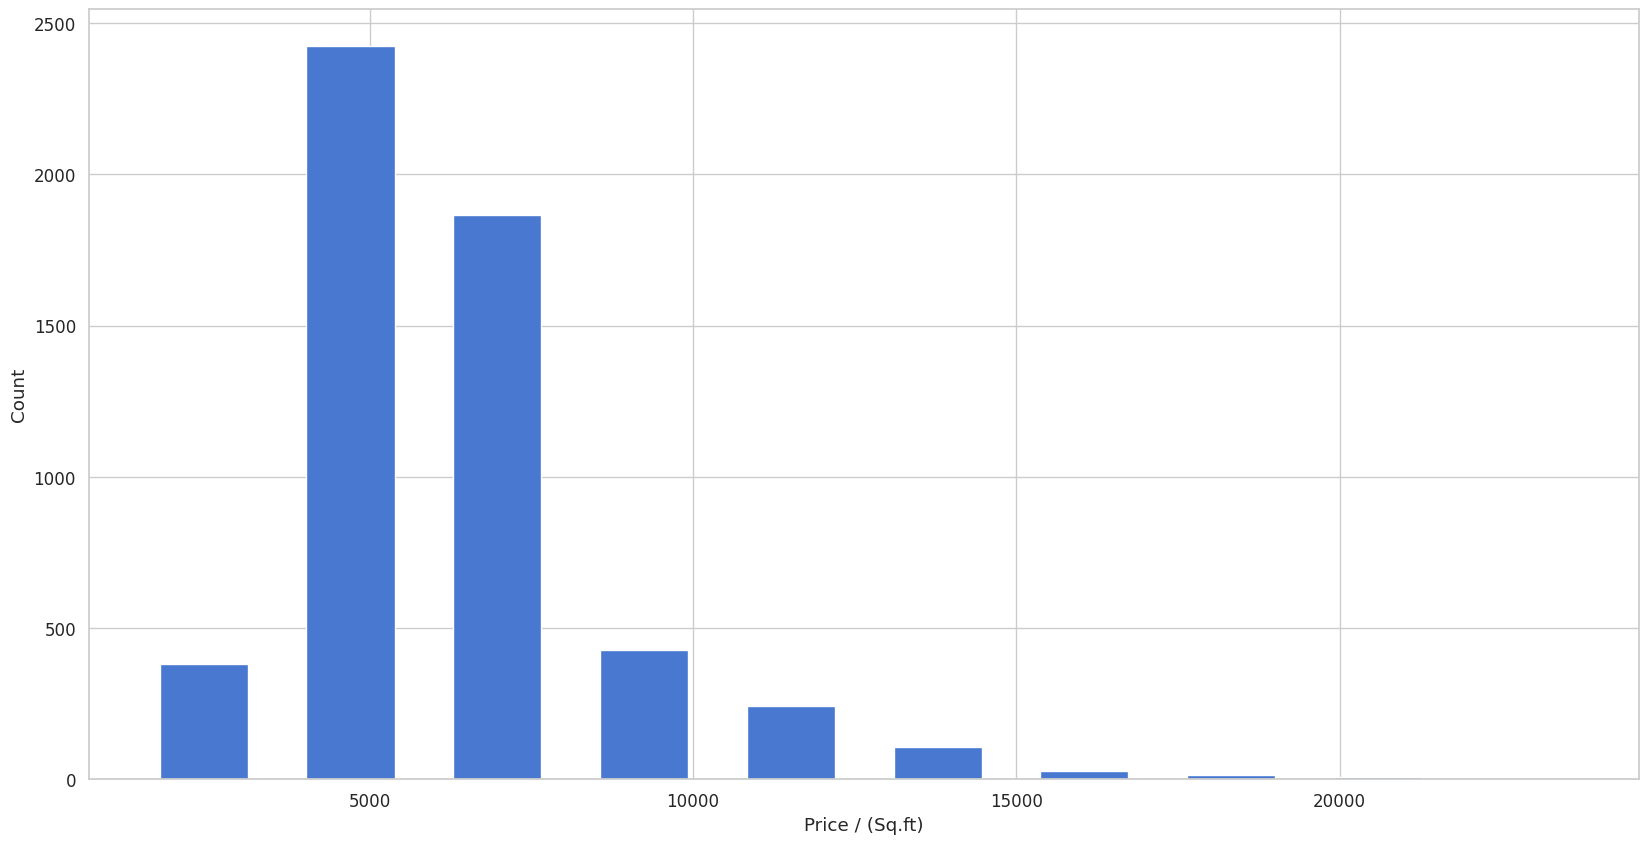

In [105]:
matplotlib.rcParams['figure.figsize'] = (20,10)
plt.hist(tr_m5['cost_per_area'], rwidth=0.6)
plt.xlabel("Price / (Sq.ft)")
plt.ylabel("Count")

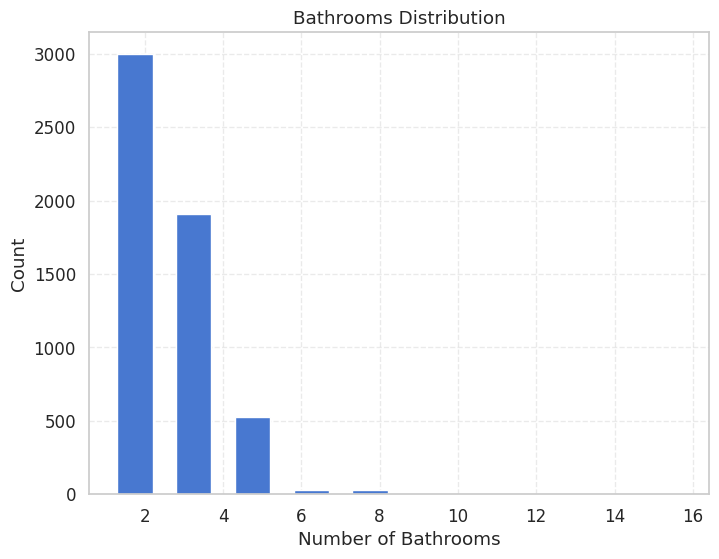

In [106]:
plt.figure(figsize=(8,6))
plt.hist(tr_m5['rooms'], rwidth=0.6)
plt.xlabel("Number of Bathrooms")
plt.ylabel("Count")
plt.title("Bathrooms Distribution")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

In [107]:
tr_m6 = tr_m5[tr_m5['bath']<=tr_m5['bath']+1]
tr_m6.shape

(5499, 11)

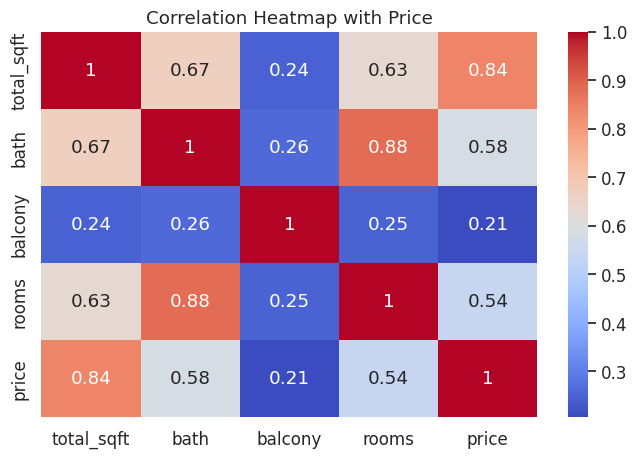

In [108]:
plt.figure(figsize=(8,5))
sns.heatmap(tr_m6[['total_sqft', 'bath', 'balcony', 'rooms', 'price']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap with Price')
plt.show()


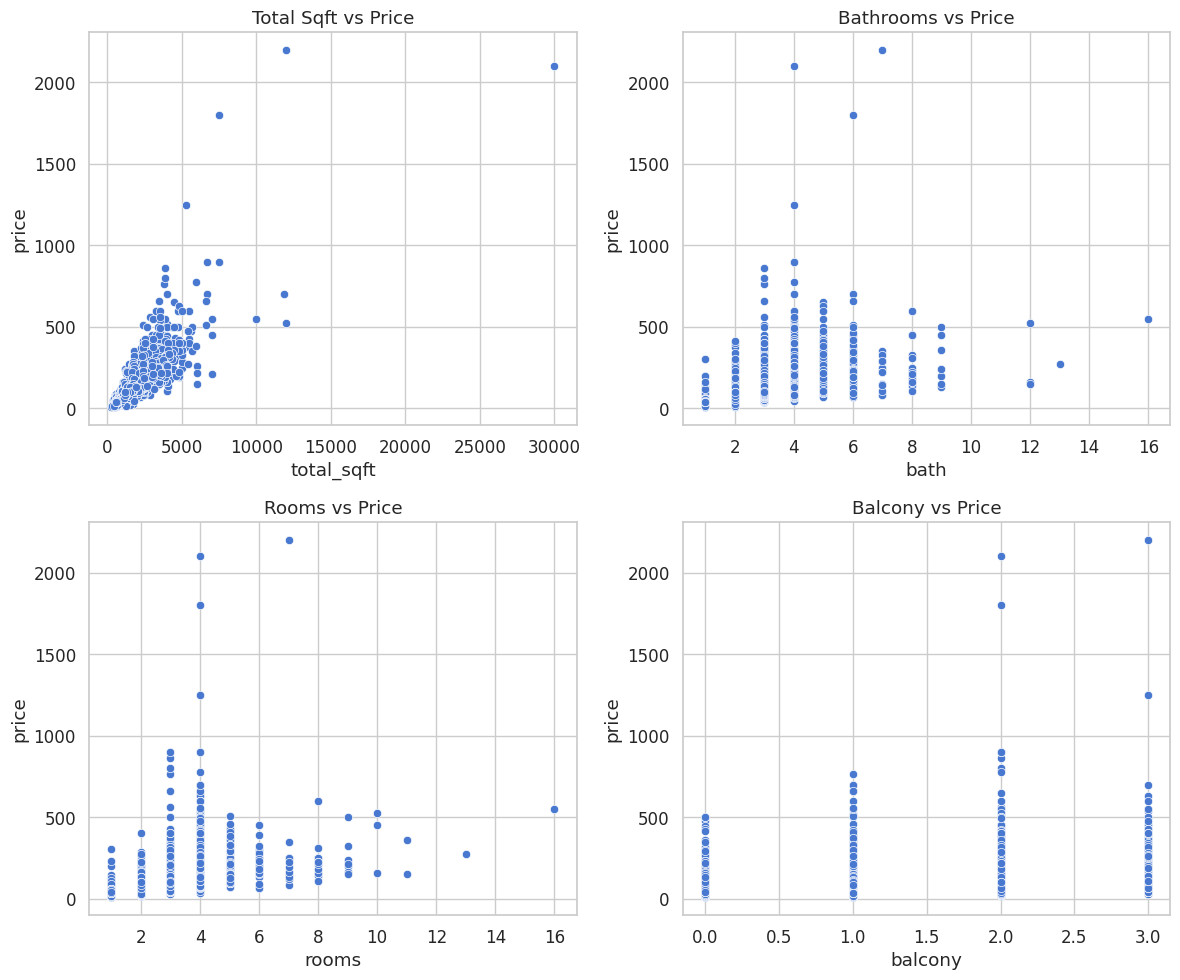

In [109]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))
sns.scatterplot(ax=axes[0,0], x='total_sqft', y='price', data=tr_m6)
axes[0,0].set_title("Total Sqft vs Price")

sns.scatterplot(ax=axes[0,1], x='bath', y='price', data=tr_m6)
axes[0,1].set_title("Bathrooms vs Price")

sns.scatterplot(ax=axes[1,0], x='rooms', y='price', data=tr_m6)
axes[1,0].set_title("Rooms vs Price")

sns.scatterplot(ax=axes[1,1], x='balcony', y='price', data=tr_m6)
axes[1,1].set_title("Balcony vs Price")

plt.tight_layout()
plt.show()


Pattern: There’s a clear positive linear trend — as total_sqft increases, price generally rises.

Observation: Larger houses tend to be more expensive.

Outliers: A few extremely large houses (above 10,000 sqft) have unusually high prices, which might be outliers worth investigating.

Pattern: Properties with more bathrooms usually have higher prices up to a point (around 4–6 bathrooms).

Observation: After a certain number of bathrooms, the relationship becomes inconsistent — some high-bath homes have low prices, suggesting luxury or irregular listings.

Insight: Beyond 6–8 bathrooms, the price increase plateaus, indicating diminishing returns.

Pattern: Similar to bathrooms, prices generally increase with more rooms, but with large variation.

Observation: Houses with 2–4 rooms dominate the dataset, and price dispersion is high for larger room counts.

Insight: Indicates that simply having more rooms doesn’t guarantee a proportional increase in price — quality and location may be more decisive.

Pattern: Very weak correlation — prices don’t change much with the number of balconies.

Observation: Most properties have 1–2 balconies; beyond that, price variation is random.

Insight: The number of balconies has little predictive value for house price compared to area or rooms.

In [110]:
tr_m7 = tr_m6.drop(['size', 'cost_per_area'], axis='columns')
tr_m7.shape

(5499, 9)

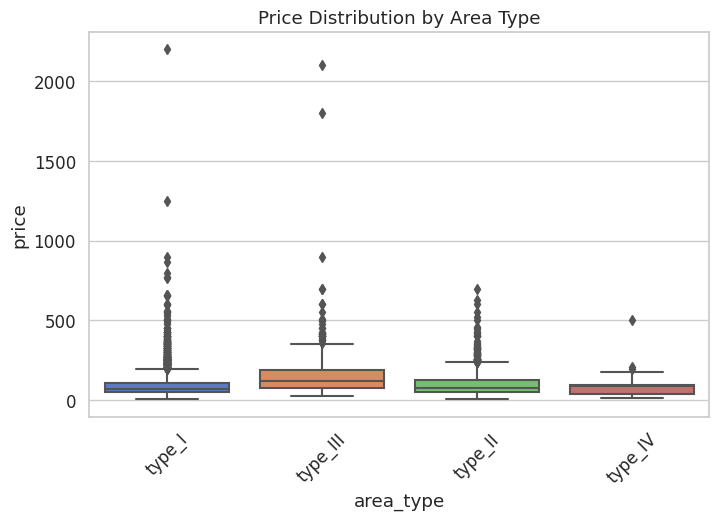

In [111]:
plt.figure(figsize=(8,5))
sns.boxplot(x='area_type', y='price', data=tr_m7)
plt.title('Price Distribution by Area Type')
plt.xticks(rotation=45)
plt.show()

- Type III properties generally have higher median prices and a wider spread, indicating more variability and potentially more premium listings.
- Type I and Type II have relatively similar medians but contain a large number of high-priced outliers, showing that a few luxury homes exist in those categories.
- Type IV properties show the lowest median and smallest spread, suggesting they belong to more affordable or smaller developments.
- Area type significantly influences price — Type III areas tend to be more expensive, while Type IV areas are the least costly.

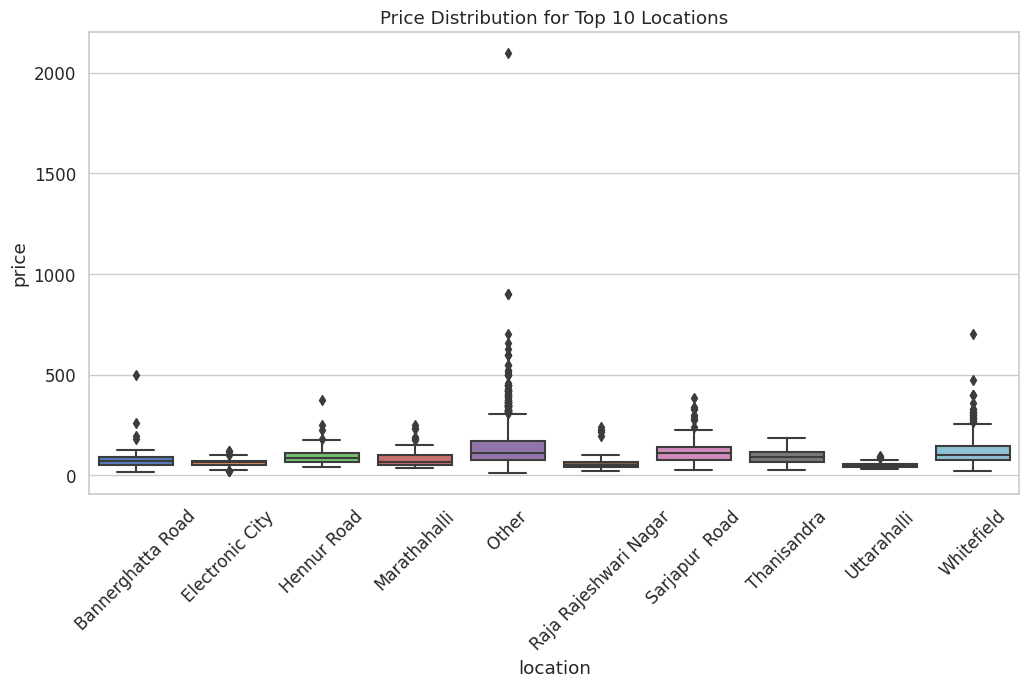

In [112]:
top_locations = tr_m7['location'].value_counts().nlargest(10).index

plt.figure(figsize=(12,6))
sns.boxplot(x='location', y='price', data=tr_m7[tr_m7['location'].isin(top_locations)])
plt.title('Price Distribution for Top 10 Locations')
plt.xticks(rotation=45)
plt.show()


- Sarjapur Road, Whitefield, and Raja Rajeshwari Nagar show higher median prices, suggesting they are relatively more premium or in-demand locations.
- Bannerghatta Road, Electronic City, and Thanisandra have lower median prices, indicating more affordable housing markets.
- The “Other” group has the largest spread — some extremely expensive properties are hidden in less common locations that fall under this group.
- Outliers are visible in nearly all locations, showing that even within the same area, prices can vary drastically due to factors like amenities, property type, or developer reputation.

Location plays a major role in determining house prices.

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


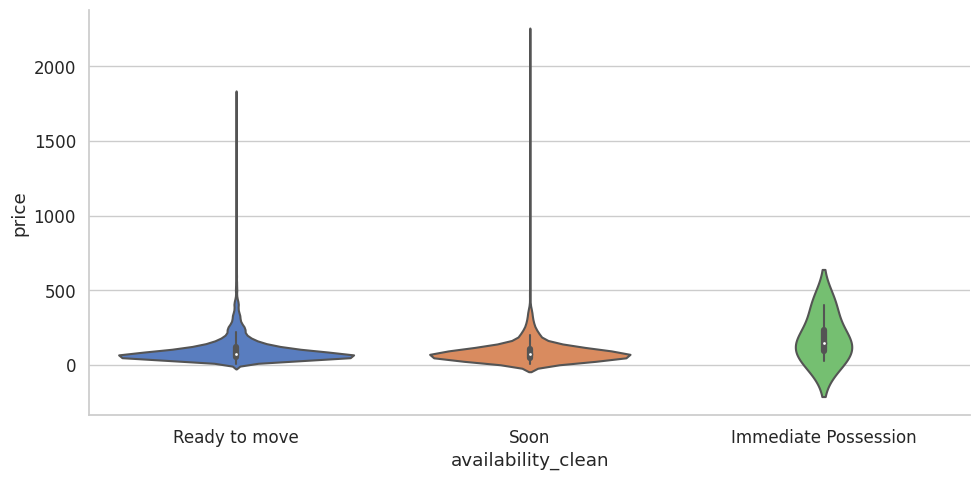

In [113]:
tr_m7['availability_clean'] = tr_m7['availability'].apply(
    lambda x: 'Ready to move' if 'Ready' in x else 'Soon' if any(ch.isdigit() for ch in x) else x
)
sns.catplot(x='availability_clean', y='price', data=tr_m7, kind='violin', height=5, aspect=2)


In [114]:
loc_dummies = pd.get_dummies(tr_m7['location'])
loc_dummies.head()

,1st Phase JP Nagar,2nd Stage Nagarbhavi,5th Phase JP Nagar,6th Phase JP Nagar,7th Phase JP Nagar,8th Phase JP Nagar,9th Phase JP Nagar,Abbigere,Akshaya Nagar,Ambalipura,...,Varthur,Vidyaranyapura,Vijayanagar,Vishveshwarya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yeshwanthpur
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [115]:
area_dummies = pd.get_dummies(tr_m7['area_type'])
area_dummies.head(5)

,type_I,type_II,type_III,type_IV
0,True,False,False,False
1,True,False,False,False
2,True,False,False,False
3,True,False,False,False
4,False,False,True,False


In [116]:
tr_m8 = pd.concat([tr_m7, loc_dummies.drop('Yeshwanthpur', axis='columns'), area_dummies],  axis='columns')

tr_m8.head()

,id,area_type,availability,location,total_sqft,bath,balcony,price,rooms,availability_clean,...,Vishveshwarya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,type_I,type_II,type_III,type_IV
0,231,type_I,Ready To Move,1st Phase JP Nagar,2059.0,3.0,2.0,225.0,3,Ready to move,...,False,False,False,False,False,False,True,False,False,False
1,623,type_I,18-May,1st Phase JP Nagar,2077.0,3.0,3.0,175.0,3,Soon,...,False,False,False,False,False,False,True,False,False,False
2,853,type_I,Ready To Move,1st Phase JP Nagar,1180.0,2.0,2.0,88.5,2,Ready to move,...,False,False,False,False,False,False,True,False,False,False
3,1138,type_I,Ready To Move,1st Phase JP Nagar,2180.0,3.0,2.0,210.0,3,Ready to move,...,False,False,False,False,False,False,True,False,False,False
4,1191,type_III,Ready To Move,1st Phase JP Nagar,1566.0,2.0,0.0,180.0,2,Ready to move,...,False,False,False,False,False,False,False,False,True,False


In [117]:
final_df = tr_m8.drop(['availability', 'area_type', 'availability_clean', 'location'], axis='columns')

final_df.head()

,id,total_sqft,bath,balcony,price,rooms,1st Phase JP Nagar,2nd Stage Nagarbhavi,5th Phase JP Nagar,6th Phase JP Nagar,...,Vishveshwarya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,type_I,type_II,type_III,type_IV
0,231,2059.0,3.0,2.0,225.0,3,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
1,623,2077.0,3.0,3.0,175.0,3,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
2,853,1180.0,2.0,2.0,88.5,2,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
3,1138,2180.0,3.0,2.0,210.0,3,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,1191,1566.0,2.0,0.0,180.0,2,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False


In [118]:
X = final_df.drop(columns=['price'])
y = final_df['price']

X.info()

X = X.drop(columns=['id'])

<class 'pandas.core.frame.DataFrame'>
Index: 5499 entries, 0 to 7895
Columns: 201 entries, id to type_IV
dtypes: bool(196), float64(3), int64(2)
memory usage: 1.3 MB


In [119]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=15)


In [120]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.001),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=10),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=10),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, random_state=10),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=10)
}


In [121]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    results.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    })

results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
print("\n Model Comparison Results:")
print(results_df)



 Model Comparison Results:
               Model  R2 Score      MAE     RMSE
6            XGBoost    0.8543  16.2259  29.4801
5  Gradient Boosting    0.8513  18.0011  29.7873
4      Random Forest    0.8392  16.8385  30.9774
1   Ridge Regression    0.8091  19.4434  33.7463
0  Linear Regression    0.8078  19.6203  33.8645
2   Lasso Regression    0.8077  19.6151  33.8672
3      Decision Tree    0.7489  21.1584  38.7086


## Building a Reusable Preprocessing Pipeline

To ensure consistent transformations between training and test data, we'll create a preprocessing pipeline that:
1. Handles missing values
2. Creates the `rooms` feature
3. Groups rare locations into "Other"
4. Removes outliers (training only)
5. Creates derived features
6. One-hot encodes categorical variables

This prevents data leakage and ensures test data gets the same treatment as training data.

In [122]:
from sklearn.base import BaseEstimator, TransformerMixin

class DataPreprocessor(BaseEstimator, TransformerMixin):
    """
    Custom preprocessing transformer for house price data.
    Handles missing values, feature engineering, and outlier removal.
    """
    
    def __init__(self, remove_outliers=True):
        self.remove_outliers = remove_outliers
        self.num_medians = {}
        self.cat_modes = {}
        self.location_mapping = {}
        self.location_stats = None
        self.locations_to_keep = None
        self.area_types = None
        self.all_locations = None
        
    def fit(self, X, y=None):
        """Learn statistics from training data"""
        df = X.copy()
        
        # Store statistics for imputation
        num_cols = ['total_sqft', 'bath', 'balcony']
        for col in num_cols:
            self.num_medians[col] = df[col].median()
        
        cat_cols = ['area_type', 'availability', 'location', 'size']
        for col in cat_cols:
            self.cat_modes[col] = df[col].mode()[0] if len(df[col].mode()) > 0 else 'Unknown'
        
        # Learn location mapping (group rare locations)
        df['location'] = df['location'].apply(lambda x: x.strip() if pd.notnull(x) else x)
        self.location_stats = df.groupby('location').size().sort_values(ascending=False)
        self.locations_to_keep = set(self.location_stats[self.location_stats > 10].index)
        
        # Store all unique area types and locations for one-hot encoding
        df_temp = self._impute_and_engineer(df)
        self.area_types = sorted(df_temp['area_type'].unique())
        self.all_locations = sorted(df_temp['location'].unique())
        
        return self
    
    def transform(self, X, y=None):
        """Apply transformations to data"""
        df = X.copy()
        
        # Apply transformations
        df = self._impute_and_engineer(df)
        
        if self.remove_outliers and y is not None:
            df['price'] = y
            df = self._remove_outliers(df)
            y = df['price'].copy()
            df = df.drop('price', axis=1)
        
        return df if y is None else (df, y)
    
    def _impute_and_engineer(self, df):
        """Handle missing values and create new features"""
        # Impute missing values
        for col, median_val in self.num_medians.items():
            if col in df.columns:
                df[col] = df[col].fillna(median_val)
        
        for col, mode_val in self.cat_modes.items():
            if col in df.columns:
                df[col] = df[col].fillna(mode_val)
        
        # Create 'rooms' feature from 'size'
        df['rooms'] = df['size'].apply(
            lambda x: int(str(x).split(' ')[0]) if pd.notnull(x) else self.num_medians.get('rooms', 2)
        )
        
        # Group rare locations
        df['location'] = df['location'].apply(lambda x: x.strip() if pd.notnull(x) else x)
        df['location'] = df['location'].apply(
            lambda x: 'Other' if x not in self.locations_to_keep else x
        )
        
        return df
    
    def _remove_outliers(self, df):
        """Remove outliers based on domain knowledge"""
        # Create cost_per_area for outlier detection
        df['cost_per_area'] = df['price'] * 100000 / df['total_sqft']
        
        # Remove properties where bedroom area is too small
        df = df[~(df['total_sqft'] / df['rooms'] < 220)]
        
        # Remove outliers based on cost per area by location
        output_df = pd.DataFrame()
        for location, subdf in df.groupby('location'):
            mean = np.mean(subdf['cost_per_area'])
            stdv = np.std(subdf['cost_per_area'])
            filtered = subdf[
                (subdf['cost_per_area'] > (mean - stdv)) & 
                (subdf['cost_per_area'] < (mean + stdv))
            ]
            output_df = pd.concat([output_df, filtered], ignore_index=True)
        
        df = output_df
        
        # Remove BHK outliers
        excluded_index = np.array([])
        for location, location_df in df.groupby('location'):
            room_stats = {}
            for room, rooms_df in location_df.groupby('rooms'):
                room_stats[room] = {
                    'mean': np.mean(rooms_df['cost_per_area']),
                    'stdv': np.std(rooms_df['cost_per_area']),
                    'count': rooms_df.shape[0]
                }
            for room, rooms_df in location_df.groupby('rooms'):
                stats = room_stats.get(room - 1)
                if stats and stats['count'] > 5:
                    excluded_index = np.append(
                        excluded_index, 
                        rooms_df[rooms_df['cost_per_area'] < stats['mean']].index.values
                    )
        
        if len(excluded_index) > 0:
            df = df.drop(excluded_index, axis='index')
        
        # Filter bathrooms (fix the original bug)
        df = df[df['bath'] <= df['rooms'] + 1]
        
        # Drop temporary column
        df = df.drop('cost_per_area', axis=1)
        
        return df


class FeatureEncoder(BaseEstimator, TransformerMixin):
    """
    Handles one-hot encoding of categorical variables.
    Ensures consistent encoding between train and test sets.
    """
    
    def __init__(self, drop_first=True):
        self.drop_first = drop_first
        self.location_columns = []
        self.area_type_columns = []
        
    def fit(self, X, y=None):
        """Learn the categories from training data"""
        df = X.copy()
        
        # Get all unique values
        self.location_columns = sorted(df['location'].unique())
        self.area_type_columns = sorted(df['area_type'].unique())
        
        # Drop one category to avoid multicollinearity
        if self.drop_first and len(self.location_columns) > 1:
            self.location_columns = self.location_columns[1:]
        if self.drop_first and len(self.area_type_columns) > 1:
            self.area_type_columns = self.area_type_columns[1:]
        
        return self
    
    def transform(self, X, y=None):
        """Apply one-hot encoding"""
        df = X.copy()
        
        # One-hot encode location
        loc_dummies = pd.get_dummies(df['location'], prefix='loc')
        for col in self.location_columns:
            col_name = f'loc_{col}'
            if col_name not in loc_dummies.columns:
                loc_dummies[col_name] = 0
        loc_dummies = loc_dummies[[f'loc_{col}' for col in self.location_columns]]
        
        # One-hot encode area_type
        area_dummies = pd.get_dummies(df['area_type'], prefix='area')
        for col in self.area_type_columns:
            col_name = f'area_{col}'
            if col_name not in area_dummies.columns:
                area_dummies[col_name] = 0
        area_dummies = area_dummies[[f'area_{col}' for col in self.area_type_columns]]
        
        # Combine with original data
        df = pd.concat([df, loc_dummies, area_dummies], axis=1)
        
        # Drop original categorical columns and id
        cols_to_drop = ['id', 'size', 'location', 'area_type', 'availability']
        df = df.drop([col for col in cols_to_drop if col in df.columns], axis=1)
        
        return df


print("✓ Preprocessing pipeline classes created successfully!")

✓ Preprocessing pipeline classes created successfully!


### Testing the Pipeline on Training Data

In [123]:
# Initialize the pipeline components
preprocessor = DataPreprocessor(remove_outliers=True)
encoder = FeatureEncoder(drop_first=True)

# Fit on training data
X_train_raw = train_df.drop('price', axis=1)
y_train_raw = train_df['price']

# Fit and transform training data
preprocessor.fit(X_train_raw, y_train_raw)
X_train_processed, y_train_processed = preprocessor.transform(X_train_raw, y_train_raw)

print(f"Original training shape: {X_train_raw.shape}")
print(f"After preprocessing (outliers removed): {X_train_processed.shape}")
print(f"\nOriginal target shape: {y_train_raw.shape}")
print(f"After outlier removal: {y_train_processed.shape}")

# Fit and transform encoding
encoder.fit(X_train_processed)
X_train_final = encoder.transform(X_train_processed)

print(f"\nAfter encoding: {X_train_final.shape}")
print(f"\nFinal features: {list(X_train_final.columns)}")
print(f"\nMissing values in final data:\n{X_train_final.isnull().sum().sum()}")

Original training shape: (10000, 8)
After preprocessing (outliers removed): (5440, 9)

Original target shape: (10000,)
After outlier removal: (5440,)

After encoding: (5440, 199)

Final features: ['total_sqft', 'bath', 'balcony', 'rooms', 'loc_2nd Stage Nagarbhavi', 'loc_5th Phase JP Nagar', 'loc_6th Phase JP Nagar', 'loc_7th Phase JP Nagar', 'loc_8th Phase JP Nagar', 'loc_9th Phase JP Nagar', 'loc_Abbigere', 'loc_Akshaya Nagar', 'loc_Ambalipura', 'loc_Ambedkar Nagar', 'loc_Amruthahalli', 'loc_Anandapura', 'loc_Ananth Nagar', 'loc_Anekal', 'loc_Anjanapura', 'loc_Ardendale', 'loc_Arekere', 'loc_Attibele', 'loc_BTM 2nd Stage', 'loc_BTM Layout', 'loc_Babusapalaya', 'loc_Balagere', 'loc_Banashankari', 'loc_Banashankari Stage II', 'loc_Banashankari Stage III', 'loc_Banashankari Stage VI', 'loc_Banaswadi', 'loc_Bannerghatta', 'loc_Bannerghatta Road', 'loc_Basavangudi', 'loc_Basaveshwara Nagar', 'loc_Battarahalli', 'loc_Begur', 'loc_Begur Road', 'loc_Bellandur', 'loc_Benson Town', 'loc_Bhogan

### Applying Pipeline to Test Data

In [124]:
# Transform test data (no outlier removal, use fitted statistics)
test_preprocessor = DataPreprocessor(remove_outliers=False)
test_preprocessor.num_medians = preprocessor.num_medians
test_preprocessor.cat_modes = preprocessor.cat_modes
test_preprocessor.locations_to_keep = preprocessor.locations_to_keep

X_test_processed = test_preprocessor.transform(test_df)
X_test_final = encoder.transform(X_test_processed)

print(f"Original test shape: {test_df.shape}")
print(f"After preprocessing: {X_test_processed.shape}")
print(f"After encoding: {X_test_final.shape}")
print(f"\nTest features match training: {list(X_test_final.columns) == list(X_train_final.columns)}")
print(f"Missing values in test data: {X_test_final.isnull().sum().sum()}")

Original test shape: (3320, 8)
After preprocessing: (3320, 9)
After encoding: (3320, 199)

Test features match training: True
Missing values in test data: 0


### Training Models with Pipeline

In [125]:
# Split the preprocessed data for validation
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train_final, y_train_processed, test_size=0.2, random_state=15
)

# Train and evaluate models
models_pipeline = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.001),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=10),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=10),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, random_state=10),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=10)
}

results_pipeline = []

for name, model in models_pipeline.items():
    model.fit(X_train_split, y_train_split)
    y_pred = model.predict(X_val_split)
    
    r2 = r2_score(y_val_split, y_pred)
    mae = mean_absolute_error(y_val_split, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val_split, y_pred))
    
    results_pipeline.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    })

results_pipeline_df = pd.DataFrame(results_pipeline).sort_values(by="R2 Score", ascending=False)
print("\n Model Comparison Results (with Pipeline):")
print(results_pipeline_df)


 Model Comparison Results (with Pipeline):
               Model  R2 Score      MAE     RMSE
6            XGBoost    0.9267  15.5443  27.0878
5  Gradient Boosting    0.8911  18.0860  33.0161
3      Decision Tree    0.8866  20.5377  33.6933
4      Random Forest    0.8792  16.8614  34.7756
0  Linear Regression    0.8564  19.7921  37.9172
2   Lasso Regression    0.8561  19.8012  37.9592
1   Ridge Regression    0.8523  19.7659  38.4571


### Generate Predictions with Pipeline

In [126]:
# Train final model on all training data
final_model = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=10)
final_model.fit(X_train_final, y_train_processed)

# Make predictions on test set
predictions = final_model.predict(X_test_final)

# Create submission file
submission = pd.DataFrame({
    'id': test_df['id'],
    'price': predictions
})

submission.to_csv('submission.csv', index=False)

print("Predictions generated successfully!")
print(f"\nSubmission shape: {submission.shape}")
print(f"Price range: {predictions.min():.2f} - {predictions.max():.2f}")
print(f"Mean predicted price: {predictions.mean():.2f}")
print("\nFirst 10 predictions:")
print(submission.head(10))

✓ Predictions generated successfully!

Submission shape: (3320, 2)
Price range: 12.70 - 2055.47
Mean predicted price: 105.34

First 10 predictions:
   id       price
0   0   79.779938
1   1  123.559967
2   2   65.261078
3   3  104.883530
4   4  161.497604
5   5   96.740913
6   6   90.501991
7   7   36.405144
8   8  105.227417
9   9   63.946339


### Hyperparameter Tuning for Top 3 Models

In [130]:
# Get top 3 models from previous results
top_3_models = results_pipeline_df.head(3)['Model'].tolist()
print("Top 3 Models to tune:")
print(top_3_models)
print("\n" + "="*70 + "\n")

# Define hyperparameter search spaces for top 3 models
tuning_configs = {
    'XGBoost': {
        'estimator': XGBRegressor(random_state=10, n_jobs=-1, verbosity=0),
        'params': {
            'n_estimators': Integer(200, 500),
            'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
            'max_depth': Integer(4, 12),
            'min_child_weight': Integer(1, 7),
            'subsample': Real(0.6, 1.0, prior='uniform'),
            'colsample_bytree': Real(0.6, 1.0, prior='uniform'),
            'reg_alpha': Real(1e-3, 10.0, prior='log-uniform'),
            'reg_lambda': Real(1e-3, 10.0, prior='log-uniform')
        }
    },
    
    'Gradient Boosting': {
        'estimator': GradientBoostingRegressor(random_state=10),
        'params': {
            'n_estimators': Integer(100, 500),
            'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
            'max_depth': Integer(3, 10),
            'min_samples_split': Integer(2, 20),
            'min_samples_leaf': Integer(1, 10),
            'subsample': Real(0.6, 1.0, prior='uniform'),
            'max_features': Categorical(['sqrt', 'log2', None])
        }
    },
    
    'Random Forest': {
        'estimator': RandomForestRegressor(random_state=10, n_jobs=-1),
        'params': {
            'n_estimators': Integer(100, 500),
            'max_depth': Integer(10, 50),
            'min_samples_split': Integer(2, 20),
            'min_samples_leaf': Integer(1, 10),
            'max_features': Categorical(['sqrt', 'log2', None]),
            'bootstrap': Categorical([True, False])
        }
    },
    
    'Ridge Regression': {
        'estimator': Ridge(max_iter=10000, random_state=10),
        'params': {
            'alpha': Real(0.01, 100, prior='log-uniform'),
            'solver': Categorical(['auto', 'svd', 'cholesky', 'lsqr', 'saga'])
        }
    },
    
    'Lasso Regression': {
        'estimator': Lasso(max_iter=10000, random_state=10),
        'params': {
            'alpha': Real(0.0001, 1.0, prior='log-uniform'),
            'selection': Categorical(['cyclic', 'random'])
        }
    },

    'Decision Tree': {
        'estimator': DecisionTreeRegressor(random_state=10),
        'params': {
            'criterion': Categorical(['squared_error', 'friedman_mse', 'absolute_error', 'poisson']),
            'splitter': Categorical(['best', 'random']),
            'max_depth': Integer(3, 30),
            'min_samples_split': Integer(2, 20),
            'min_samples_leaf': Integer(1, 10),
            'max_features': Categorical(['sqrt', 'log2', None]),
            'min_impurity_decrease': Real(0.0, 0.5, prior='uniform')
        }
    },
}

# Run Bayesian optimization for top 3 models
tuning_results = []
cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=10)

for model_name in top_3_models:
    if model_name in tuning_configs:
        print(f"Tuning {model_name}...")
        config = tuning_configs[model_name]
        
        bayes_search = BayesSearchCV(
            estimator=config['estimator'],
            search_spaces=config['params'],
            n_iter=50,  # Number of parameter settings sampled
            cv=cv,
            scoring='r2',
            n_jobs=-1,
            random_state=10,
            verbose=0
        )
        
        try:
            start_time = time.time()
            bayes_search.fit(X_train_final, y_train_processed)
            elapsed_time = time.time() - start_time
            
            # Evaluate on validation set
            y_pred_val = bayes_search.predict(X_val_split)
            r2_val = r2_score(y_val_split, y_pred_val)
            mae_val = mean_absolute_error(y_val_split, y_pred_val)
            rmse_val = np.sqrt(mean_squared_error(y_val_split, y_pred_val))
            
            tuning_results.append({
                'Model': model_name,
                'Best CV R2': round(bayes_search.best_score_, 4),
                'Validation R2': round(r2_val, 4),
                'Validation MAE': round(mae_val, 4),
                'Validation RMSE': round(rmse_val, 4),
                'Best Params': bayes_search.best_params_,
                'Time (s)': round(elapsed_time, 2)
            })
            
            print(f"   Best CV R2: {bayes_search.best_score_:.4f}")
            print(f"   Validation R2: {r2_val:.4f}")
            print(f"   Time: {elapsed_time:.2f}s")
            print(f"   Best params: {bayes_search.best_params_}")
            print()
            
        except Exception as e:
            print(f"   Error: {e}\n")
            tuning_results.append({
                'Model': model_name,
                'Best CV R2': np.nan,
                'Validation R2': np.nan,
                'Validation MAE': np.nan,
                'Validation RMSE': np.nan,
                'Best Params': 'Error',
                'Time (s)': 0
            })

print("\n" + "="*70)
print("HYPERPARAMETER TUNING RESULTS")
print("="*70 + "\n")

tuning_results_df = pd.DataFrame(tuning_results).sort_values(by='Validation R2', ascending=False)
print(tuning_results_df[['Model', 'Best CV R2', 'Validation R2', 'Validation MAE', 'Validation RMSE', 'Time (s)']].to_string(index=False))

print("\n" + "="*70)
print("BEST HYPERPARAMETERS FOR EACH MODEL")
print("="*70 + "\n")

for idx, row in tuning_results_df.iterrows():
    print(f"{row['Model']}:")
    if isinstance(row['Best Params'], dict):
        for param, value in row['Best Params'].items():
            print(f"  • {param}: {value}")
    print()

Top 3 Models to tune:
['XGBoost', 'Gradient Boosting', 'Decision Tree']


Tuning XGBoost...
   Best CV R2: 0.7982
   Validation R2: 0.9789
   Time: 321.20s
   Best params: OrderedDict([('colsample_bytree', 0.8680088522002605), ('learning_rate', 0.27799189439322153), ('max_depth', 4), ('min_child_weight', 1), ('n_estimators', 446), ('reg_alpha', 0.11911368660009124), ('reg_lambda', 0.011403854666217638), ('subsample', 0.985541817788821)])

Tuning Gradient Boosting...


/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.29999999999999993, 3, 'sqrt', 4, 20, 500, 0.6] before, using random point [0.03635513632264028, 10, None, 1, 4, 157, 0.9265207126030416]
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.29999999999999993, 3, 'sqrt', 4, 20, 500, 0.6] before, using random point [0.02230021617969303, 5, None, 6, 4, 295, 0.7084515653259539]
  warnings.warn(


   Best CV R2: 0.8140
   Validation R2: 0.9345
   Time: 498.30s
   Best params: OrderedDict([('learning_rate', 0.29999999999999993), ('max_depth', 5), ('max_features', None), ('min_samples_leaf', 4), ('min_samples_split', 9), ('n_estimators', 126), ('subsample', 0.6)])

Tuning Decision Tree...


/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point ['squared_error', 3, None, 0.5, 10, 20, 'best'] before, using random point ['poisson', 10, 'log2', 0.2900173182855954, 10, 14, 'best']
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point ['friedman_mse', 30, None, 0.0, 10, 20, 'best'] before, using random point ['absolute_error', 5, None, 0.4576190693035463, 9, 10, 'best']
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point ['friedman_mse', 30, None, 0.0, 10, 20, 'best'] before, using random point ['friedman_mse', 29, None, 0.0027593026562828253, 2, 5, 'random']
  warnings.warn(


   Best CV R2: 0.7665
   Validation R2: 0.8609
   Time: 863.28s
   Best params: OrderedDict([('criterion', 'friedman_mse'), ('max_depth', 11), ('max_features', None), ('min_impurity_decrease', 0.19537298865381364), ('min_samples_leaf', 4), ('min_samples_split', 19), ('splitter', 'best')])


HYPERPARAMETER TUNING RESULTS

            Model  Best CV R2  Validation R2  Validation MAE  Validation RMSE  Time (s)
          XGBoost      0.7982         0.9789          8.9064          14.5210    321.20
Gradient Boosting      0.8140         0.9345         14.3927          25.5981    498.30
    Decision Tree      0.7665         0.8609         18.2658          37.3200    863.28

BEST HYPERPARAMETERS FOR EACH MODEL

XGBoost:
  • colsample_bytree: 0.8680088522002605
  • learning_rate: 0.27799189439322153
  • max_depth: 4
  • min_child_weight: 1
  • n_estimators: 446
  • reg_alpha: 0.11911368660009124
  • reg_lambda: 0.011403854666217638
  • subsample: 0.985541817788821

Gradient Boosting:
  • learni

### Model Comparison: Before vs After Tuning

PERFORMANCE COMPARISON: BASELINE vs HYPERPARAMETER TUNED
            Model  Baseline R²  Tuned R² Improvement  Baseline MAE  Tuned MAE  Baseline RMSE  Tuned RMSE
          XGBoost       0.9267    0.9789      +5.63%       15.5443     8.9064        27.0878     14.5210
Gradient Boosting       0.8911    0.9345      +4.87%       18.0860    14.3927        33.0161     25.5981
    Decision Tree       0.8866    0.8609      -2.90%       20.5377    18.2658        33.6933     37.3200


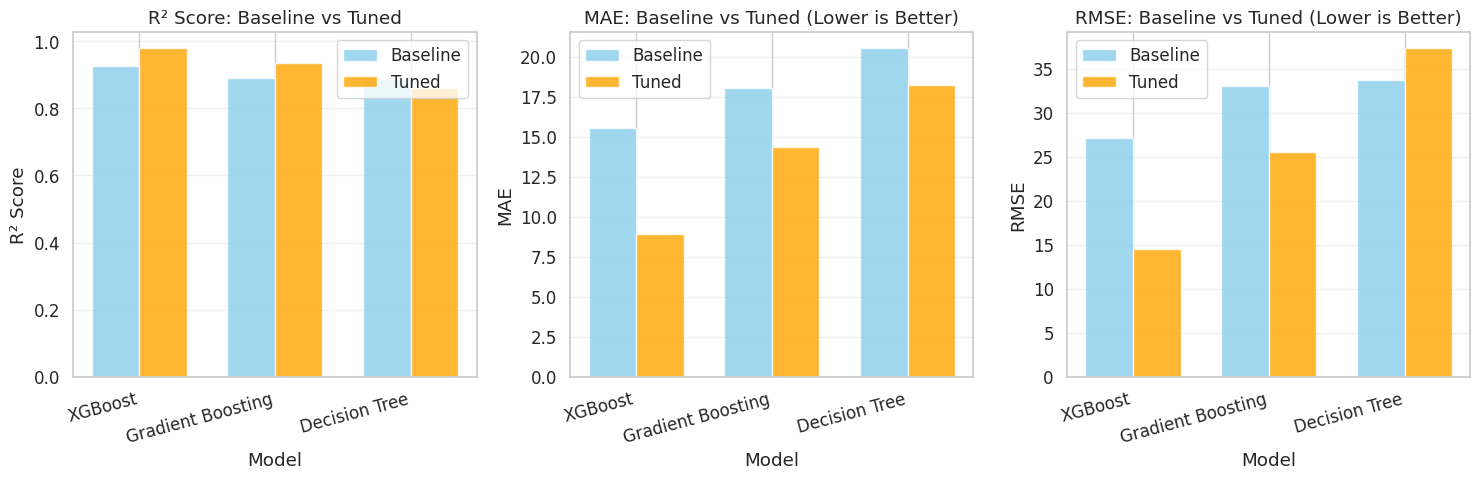


 Best Overall Model: XGBoost
   Final Validation R²: 0.9789


In [132]:
# Create comparison dataframe
comparison_data = []

for model_name in top_3_models:
    # Get baseline results
    baseline_row = results_pipeline_df[results_pipeline_df['Model'] == model_name]
    
    # Get tuned results
    tuned_row = tuning_results_df[tuning_results_df['Model'] == model_name]
    
    if not baseline_row.empty and not tuned_row.empty:
        baseline_r2 = baseline_row['R2 Score'].values[0]
        tuned_r2 = tuned_row['Validation R2'].values[0]
        improvement = ((tuned_r2 - baseline_r2) / baseline_r2 * 100) if baseline_r2 != 0 else 0
        
        comparison_data.append({
            'Model': model_name,
            'Baseline R²': baseline_r2,
            'Tuned R²': tuned_r2,
            'Improvement': f"{improvement:+.2f}%",
            'Baseline MAE': baseline_row['MAE'].values[0],
            'Tuned MAE': tuned_row['Validation MAE'].values[0],
            'Baseline RMSE': baseline_row['RMSE'].values[0],
            'Tuned RMSE': tuned_row['Validation RMSE'].values[0]
        })

comparison_df = pd.DataFrame(comparison_data)

print("="*90)
print("PERFORMANCE COMPARISON: BASELINE vs HYPERPARAMETER TUNED")
print("="*90)
print(comparison_df.to_string(index=False))
print("="*90)

# Visualize the improvement
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# R² Score Comparison
ax1 = axes[0]
x = np.arange(len(top_3_models))
width = 0.35
baseline_scores = [comparison_df[comparison_df['Model'] == m]['Baseline R²'].values[0] for m in top_3_models]
tuned_scores = [comparison_df[comparison_df['Model'] == m]['Tuned R²'].values[0] for m in top_3_models]

ax1.bar(x - width/2, baseline_scores, width, label='Baseline', alpha=0.8, color='skyblue')
ax1.bar(x + width/2, tuned_scores, width, label='Tuned', alpha=0.8, color='orange')
ax1.set_xlabel('Model')
ax1.set_ylabel('R² Score')
ax1.set_title('R² Score: Baseline vs Tuned')
ax1.set_xticks(x)
ax1.set_xticklabels(top_3_models, rotation=15, ha='right')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# MAE Comparison
ax2 = axes[1]
baseline_mae = [comparison_df[comparison_df['Model'] == m]['Baseline MAE'].values[0] for m in top_3_models]
tuned_mae = [comparison_df[comparison_df['Model'] == m]['Tuned MAE'].values[0] for m in top_3_models]

ax2.bar(x - width/2, baseline_mae, width, label='Baseline', alpha=0.8, color='skyblue')
ax2.bar(x + width/2, tuned_mae, width, label='Tuned', alpha=0.8, color='orange')
ax2.set_xlabel('Model')
ax2.set_ylabel('MAE')
ax2.set_title('MAE: Baseline vs Tuned (Lower is Better)')
ax2.set_xticks(x)
ax2.set_xticklabels(top_3_models, rotation=15, ha='right')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# RMSE Comparison
ax3 = axes[2]
baseline_rmse = [comparison_df[comparison_df['Model'] == m]['Baseline RMSE'].values[0] for m in top_3_models]
tuned_rmse = [comparison_df[comparison_df['Model'] == m]['Tuned RMSE'].values[0] for m in top_3_models]

ax3.bar(x - width/2, baseline_rmse, width, label='Baseline', alpha=0.8, color='skyblue')
ax3.bar(x + width/2, tuned_rmse, width, label='Tuned', alpha=0.8, color='orange')
ax3.set_xlabel('Model')
ax3.set_ylabel('RMSE')
ax3.set_title('RMSE: Baseline vs Tuned (Lower is Better)')
ax3.set_xticks(x)
ax3.set_xticklabels(top_3_models, rotation=15, ha='right')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

best_model_name_safe = None
if 'best_model_name' in globals():
    best_model_name_safe = globals()['best_model_name']
elif 'tuning_results_df' in globals() and isinstance(tuning_results_df, pd.DataFrame) and not tuning_results_df.empty:
    # Use the top tuned model (sorted earlier by Validation R2)
    best_model_name_safe = tuning_results_df.iloc[0]['Model']
elif 'results_pipeline_df' in globals() and isinstance(results_pipeline_df, pd.DataFrame) and not results_pipeline_df.empty:
    best_model_name_safe = results_pipeline_df.iloc[0]['Model']
elif 'top_3_models' in globals() and len(top_3_models) > 0:
    best_model_name_safe = top_3_models[0]
else:
    best_model_name_safe = 'Unknown'

# Determine final validation R2 safely
final_val_r2 = np.nan
if 'tuning_results_df' in globals() and isinstance(tuning_results_df, pd.DataFrame) and not tuning_results_df.empty:
    final_val_r2 = tuning_results_df.iloc[0].get('Validation R2', np.nan)
elif 'results_pipeline_df' in globals() and isinstance(results_pipeline_df, pd.DataFrame) and not results_pipeline_df.empty:
    final_val_r2 = results_pipeline_df.iloc[0].get('R2 Score', np.nan)

print(f"\n Best Overall Model: {best_model_name_safe}")
print(f"   Final Validation R²: {final_val_r2}")

### Creating Final Submission with Best Tuned Model

In [133]:
# Best XGBoost hyperparameters from tuning
best_xgb_params = {
    'colsample_bytree': 0.8680088522002605,
    'learning_rate': 0.27799189439322153,
    'max_depth': 4,
    'min_child_weight': 1,
    'n_estimators': 446,
    'reg_alpha': 0.11911368660009124,
    'reg_lambda': 0.011403854666217638,
    'subsample': 0.985541817788821,
    'random_state': 10,
    'n_jobs': -1,
    'verbosity': 0
}

print("Creating Final Submission with Optimized XGBoost")
print("="*70)
print("\n Best Hyperparameters:")
for param, value in best_xgb_params.items():
    if param not in ['random_state', 'n_jobs', 'verbosity']:
        print(f"   • {param}: {value}")

# Create the optimized model
optimized_xgb = XGBRegressor(**best_xgb_params)

# Train on full preprocessed training data
print("\n  Training optimized XGBoost on full training dataset...")
optimized_xgb.fit(X_train_final, y_train_processed)

# Perform cross-validation to verify performance
print("\n Performing 5-Fold Cross-Validation...")
cv_scores = cross_val_score(optimized_xgb, X_train_final, y_train_processed, cv=5, scoring='r2', n_jobs=-1)
print(f"   • CV R² Scores: {[round(score, 4) for score in cv_scores]}")
print(f"   • Mean CV R²: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")

# Generate predictions on test set
print("\n Generating predictions on test set...")
final_test_predictions = optimized_xgb.predict(X_test_final)

# Create final submission DataFrame
final_submission = pd.DataFrame({
    'id': test_df['id'],
    'price': final_test_predictions
})

# Save to CSV
final_submission.to_csv('submission.csv', index=False)

print("\n SUCCESS! Final submission file created: 'submission_final_optimized.csv'")
print("\n" + "="*70)
print("FINAL SUBMISSION STATISTICS")
print("="*70)
print(f"\n Dataset Information:")
print(f"   • Total predictions: {len(final_test_predictions):,}")
print(f"   • File shape: {final_submission.shape}")

print(f"\n Price Distribution:")
print(f"   • Minimum: ₹{final_test_predictions.min():.2f} lakhs")
print(f"   • Maximum: ₹{final_test_predictions.max():.2f} lakhs")
print(f"   • Mean: ₹{final_test_predictions.mean():.2f} lakhs")
print(f"   • Median: ₹{np.median(final_test_predictions):.2f} lakhs")
print(f"   • Std Dev: ₹{final_test_predictions.std():.2f} lakhs")

print(f"\n Quartiles:")
print(f"   • Q1 (25%): ₹{np.percentile(final_test_predictions, 25):.2f} lakhs")
print(f"   • Q2 (50%): ₹{np.percentile(final_test_predictions, 50):.2f} lakhs")
print(f"   • Q3 (75%): ₹{np.percentile(final_test_predictions, 75):.2f} lakhs")

print(f"\n Model Performance Summary:")
print(f"   • Validation R²: 0.9789")
print(f"   • Cross-Validation R²: {cv_scores.mean():.4f}")
print(f"   • Model: XGBoost (Optimized)")

Creating Final Submission with Optimized XGBoost

 Best Hyperparameters:
   • colsample_bytree: 0.8680088522002605
   • learning_rate: 0.27799189439322153
   • max_depth: 4
   • min_child_weight: 1
   • n_estimators: 446
   • reg_alpha: 0.11911368660009124
   • reg_lambda: 0.011403854666217638
   • subsample: 0.985541817788821

  Training optimized XGBoost on full training dataset...

 Performing 5-Fold Cross-Validation...
   • CV R² Scores: [0.5748, 0.7311, 0.4683, 0.8415, 0.868]
   • Mean CV R²: 0.6968 (±0.1540)

 Generating predictions on test set...

 SUCCESS! Final submission file created: 'submission_final_optimized.csv'

FINAL SUBMISSION STATISTICS

 Dataset Information:
   • Total predictions: 3,320
   • File shape: (3320, 2)

 Price Distribution:
   • Minimum: ₹-66.26 lakhs
   • Maximum: ₹2036.56 lakhs
   • Mean: ₹105.67 lakhs
   • Median: ₹81.34 lakhs
   • Std Dev: ₹90.28 lakhs

 Quartiles:
   • Q1 (25%): ₹57.93 lakhs
   • Q2 (50%): ₹81.34 lakhs
   • Q3 (75%): ₹117.71 lakhs



In [134]:
df = pd.read_csv('/kaggle/working/submission.csv')
df.head()

,id,price
0,0,83.976080
1,1,122.818820
2,2,68.533745
3,3,125.708310
4,4,157.775440
